In [2]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from minmax_opt_class_mgnn import MinMaxOptProb
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh


In [3]:
a = -1
b = 1
def u0(x):
    return (-jnp.sign(x))*(b-a)/2 + (b+a)/2

# Boundary at x=-1
def u1(x):
    return 1
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return a
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

s = 0.5*(1+a)
def u_ref(t, x):
    return u0(x-s*t)


Metal device set to: Apple M4 Max


W0000 00:00:1754073934.791802 21318247 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1754073934.801867 21318247 service.cc:145] XLA service 0x600002df9200 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1754073934.801878 21318247 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1754073934.803234 21318247 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1754073934.803251 21318247 mps_client.cc:384] XLA backend will use up to 103078739968 bytes on device 0 for SimpleAllocator.


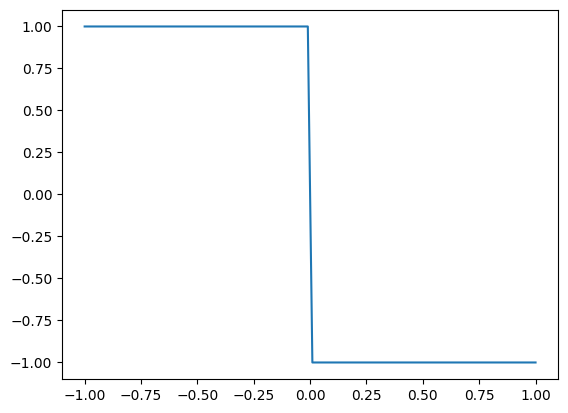

In [4]:
x = jnp.linspace(-1,1,100)
plt.plot(x, u0(x))

In [5]:
notes = '''This notebook is for computing Burgers equation with sin init, \n
featured with initial gamma = 0, f_opt_kh = 1, use_a = True, and L1reg = 0.\n
We use warmup_exponential_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 1.
In this copy, we train 5000 epoches. '''
print(notes)

This notebook is for computing Burgers equation with sin init, 

featured with initial gamma = 0, f_opt_kh = 1, use_a = True, and L1reg = 0.

We use warmup_exponential_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 1.
In this copy, we train 5000 epoches. 


In [6]:
t_min = 0
t_max = 0.5
x_min = -1
x_max = 1
N_t = 16
N_x = 16
seq_trainer = SeqMinMaxOptProb(
    num_segments=1,
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
    N_t=N_t, N_x=N_x, N_bc=2048, N_ic=4096,
    hidden_dims_list=[[64, 64, 64, 64]], seed=0, pre_epochs=5000,
    sigma=2, N_perturb=50000, k_h_rf_times=3, f_opt_kh=1,
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="minmax_burgers_standing_shock",
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes=notes, lambda_tv=0, N_t_pnts = 5*N_t, N_x_pnts = 40*N_x,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, total_grade=1, k=0, f_plot=100,
    set_wandb=True
)


wandb: Currently logged in as: haoli1 to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Using sampling method: uniform
Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.0000, 0.5000]


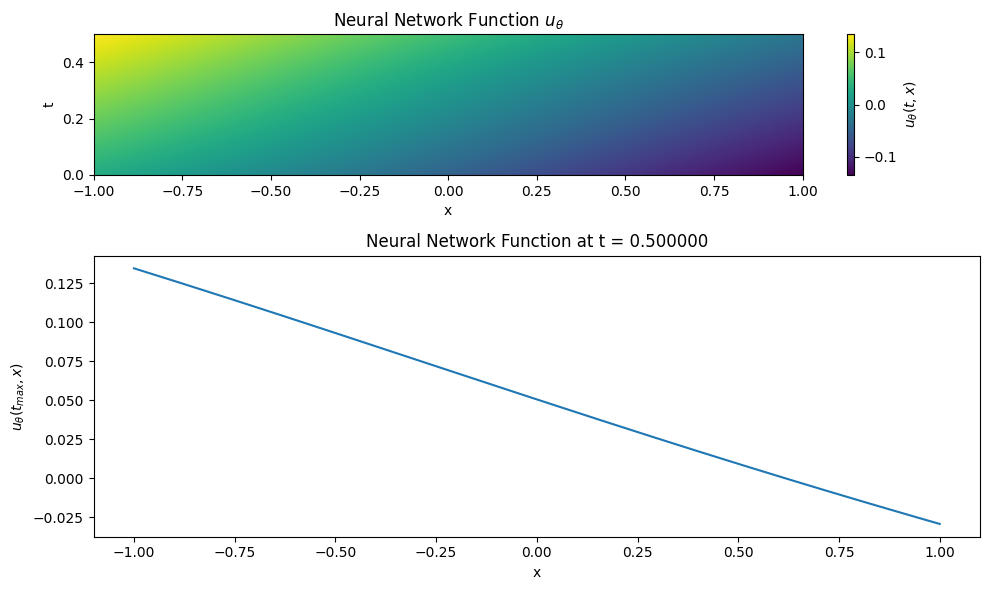


Training segment [0.0000, 0.5000]

Pre-training the network to fit v(t, x) = u0(x)
Pre-training Iter 0, Loss: 0.918866
Pre-training Iter 100, Loss: 0.052480
Pre-training Iter 200, Loss: 0.013425
Pre-training Iter 300, Loss: 0.007661
Pre-training Iter 400, Loss: 0.005348
Pre-training Iter 500, Loss: 0.004253
Pre-training Iter 600, Loss: 0.003342
Pre-training Iter 700, Loss: 0.002792
Pre-training Iter 800, Loss: 0.002580
Pre-training Iter 900, Loss: 0.002022
Pre-training Iter 1000, Loss: 0.001816
Pre-training Iter 1100, Loss: 0.002010
Pre-training Iter 1200, Loss: 0.001438
Pre-training Iter 1300, Loss: 0.001123
Pre-training Iter 1400, Loss: 0.001166
Pre-training Iter 1500, Loss: 0.000869
Pre-training Iter 1600, Loss: 0.000810
Pre-training Iter 1700, Loss: 0.000775
Pre-training Iter 1800, Loss: 0.000705
Pre-training Iter 1900, Loss: 0.000658
Pre-training Iter 2000, Loss: 0.000613
Pre-training Iter 2100, Loss: 0.000574
Pre-training Iter 2200, Loss: 0.000558
Pre-training Iter 2300, Loss: 0

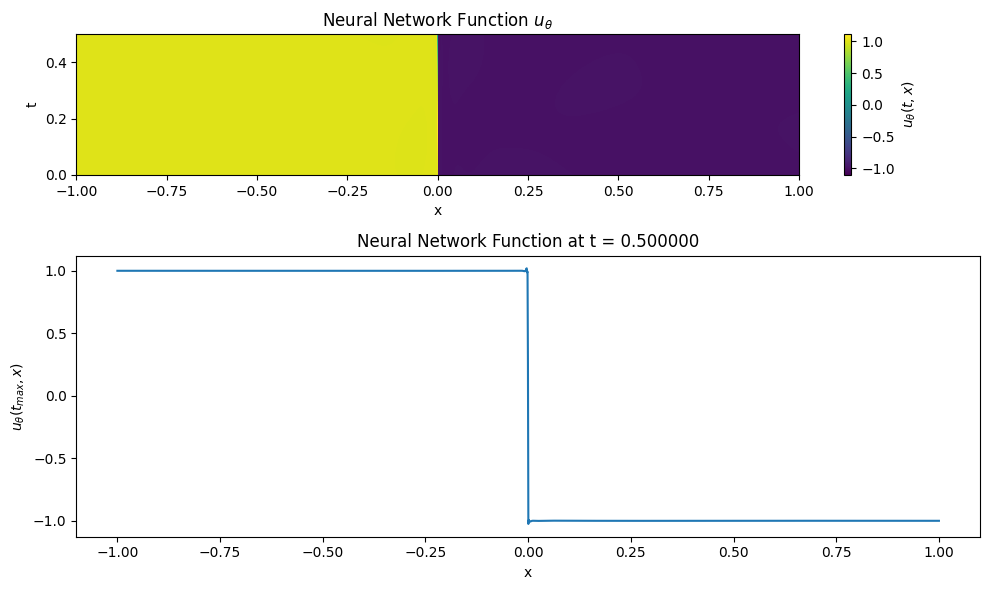


Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0


NameError: name 'inf' is not defined

In [7]:
# The is the result for a=-1, sigma=1. With pre-train. 64*64 mesh for [0, 0.5]x[-1, 1].

seq_trainer.train_seq()

plot_comparison_seperate_combined_u_theta(seq_trainer, u_ref=u_ref, ts=[0.1*i for i in range(6)], M_x=1000)
compute_errors_combined_u_theta(seq_trainer, u_ref=u_ref, )

In [ ]:
len(seq_trainer.segments)
# seg = seq_trainer.segments[0]
# plot_u_theta_mesh(
#                 model=seg.model,
#                 M_t=seg.M_t,
#                 M_x=seg.M_x,
#                 t_min=seg.t_min,
#                 t_max=seg.t_max,
#                 x_min=seg.x_min,
#                 x_max=seg.x_max,
#                 upload_fig=False,
#                 pwp=seg.pwp,
#                 vals=loss_each_elem,
#                 )

In [ ]:
seq_trainer = SeqMinMaxOptProb(
    num_segments=1,
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
    N_t=N_t, N_x=N_x, N_bc=2048, N_ic=4096,
    hidden_dims_list=[[64, 64, 64, 64]], seed=0, pre_epochs=5000,
    sigma=1, N_perturb=50000, k_h_rf_times=3, f_opt_kh=1,
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="minmax_burgers_standing_shock",
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes=notes, lambda_tv=0, N_t_pnts = 5*N_t, N_x_pnts = 40*N_x,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, total_grade=1, k=0, f_plot=100,
    set_wandb=False
)

seq_trainer.train_seq()

In [ ]:
seq_trainer.train_seq()

In [ ]:
seq_trainer.train_seq()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import gridspec

def plot_u_theta_mesh(model, params=None, M_t=1000, M_x=2000, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0, ts=None, upload_fig=False, pwp=None, avg_vals=None):
    """
    Plot the neural network function u_theta over a specified domain [t_min, t_max] x [x_min, x_max],
    and include a 1D plot of u_theta at t = t_max. Additionally, plot separate 1D snapshots for each timestamp in ts if provided.
    Optionally overlay the triangular mesh from PiecewiseLinearPolynomials and denote avg_vals on the triangles.

    Args:
        model: Neural network u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 1000).
        M_x: Number of grid points in the x-direction (default: 2000).
        t_min: Minimum value for t (default: 0.0).
        t_max: Maximum value for t (default: 1.0).
        x_min: Minimum value for x (default: 0.0).
        x_max: Maximum value for x (default: 1.0).
        ts: List or array of timestamps for which to plot individual 1D snapshots (default: None).
        upload_fig: Whether to upload the figure to wandb (default: False).
        pwp: Instance of PiecewiseLinearPolynomials to plot the mesh (default: None).
        avg_vals: Average values to denote on each triangle (default: None).
    """
    if ts is None:
        ts = []

    # Create a grid for t and x over the specified ranges
    t_grid = np.linspace(t_min, t_max, M_t)
    x_grid = np.linspace(x_min, x_max, M_x)
    t, x = np.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for batch evaluation
    tx_points = np.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Evaluate u_theta on the grid points
    if params is None:
        u_values = model.forward(tx_points)
    else:
        u_values = model.forward_with_params(params, tx_points) if hasattr(model, 'forward_with_params') else model(params, tx_points)
    u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

    # Create larger figure with two subplots for the main plot
    t_range = t_max - t_min
    fig = plt.figure(figsize=(20, 8 + 8 * t_range))
    gs = gridspec.GridSpec(2, 1, height_ratios=[t_range, 1])
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])

    # 2D color mesh plot
    pcm = ax1.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
    fig.colorbar(pcm, ax=ax1, label='$u_\\theta(t, x)$')
    ax1.set_xlabel('x')
    ax1.set_ylabel('t')
    ax1.set_title('Neural Network Function $u_\\theta$')

    # Overlay the mesh and denote avg_vals if pwp and avg_vals are provided
    if pwp is not None and avg_vals is not None:
        triangles = pwp.triangles
        for idx, tri in enumerate(triangles):
            # Plot the three edges of the triangle
            ax1.plot([tri[0][1], tri[1][1]], [tri[0][0], tri[1][0]], color='black', alpha=0.5, linewidth=0.5)
            ax1.plot([tri[1][1], tri[2][1]], [tri[1][0], tri[2][0]], color='black', alpha=0.5, linewidth=0.5)
            ax1.plot([tri[2][1], tri[0][1]], [tri[2][0], tri[0][0]], color='black', alpha=0.5, linewidth=0.5)

            # Compute the center of the triangle
            center = np.mean(tri, axis=0)

            # Denote avg_val at the center
            ax1.text(center[1], center[0], f'{avg_vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

    # 1D plot at t = t_max
    ax2.plot(x_grid, u_values[-1, :])
    ax2.set_xlabel('x')
    ax2.set_ylabel('$u_\\theta(t_{max}, x)$')
    ax2.set_title(f'Neural Network Function at t = {t_max:.2f}')

    # Adjust layout and display the main plot
    plt.tight_layout()
    # Upload the main figure to wandb
    if upload_fig:
        wandb.log({f"u_theta_tmin{t_min:.1f}_tmax_{t_max:.1f}": wandb.Image(fig)})
    plt.show()

    # Plot separate figures for each timestamp in ts
    for t_val in ts:
        # Find the closest index in t_grid
        idx = np.argmin(np.abs(t_grid - t_val))
        # Create a new figure for the snapshot
        fig, ax = plt.subplots(1, 1, figsize=(10, 4))
        ax.plot(x_grid, u_values[idx, :])
        ax.set_xlabel('x')
        ax.set_ylabel('$u_\\theta(t, x)$')
        ax.set_title(f'Neural Network Function at t = {t_val:.2f} (closest t = {t_grid[idx]:.2f})')
        plt.tight_layout()
        plt.show()

In [ ]:
model = seq_trainer.segments[0].model
pwp = seq_trainer.segments[0].pwp
params = model.mlps[0].params
optProb = seq_trainer.segments[0]

Nt = optProb.pwp.N_elements
vertices_all = optProb.pwp.triangles
mid_pnts = jnp.average(vertices_all, axis=1)


plot_u_theta_mesh(model, pwp=pwp, avg_vals=mid_pnts[:,1])

In [ ]:
model = seq_trainer.segments[0].model
pwp = seq_trainer.segments[0].pwp
params = model.mlps[0].params
optProb = seq_trainer.segments[0]

Nt = optProb.pwp.N_elements
vertices_all = optProb.pwp.triangles
u_values_all = optProb.u_eval(params, vertices_all.reshape(-1, 2)).reshape(Nt, 3)
avg_vals = jnp.average(u_values_all, axis=1)


plot_u_theta_mesh(model, pwp=pwp, avg_vals=avg_vals)

In [ ]:
jnp.average(vertices_all, axis=1)[:,1].shape

In [ ]:
avg_vals.shape

In [ ]:
data = np.load('data/burgers_sin_ref.npz')
times = data['times']
x = data['x']
u_num = data['u']  # Shape: (n_times, n_x)

In [ ]:
times[-1]

In [ ]:
idx_T = np.argmin(np.abs(times - 1.0))

In [ ]:
idx_T

In [ ]:
plot_combined_u_theta